In [2]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [3]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Data Shape: ",X.shape)
print("Target Shape: ",y.shape)
print("Target Classes: ",data.target_names)

X.head()

print("\nClass distribution:")
print(pd.Series(y).value_counts())

Data Shape:  (569, 30)
Target Shape:  (569,)
Target Classes:  ['malignant' 'benign']

Class distribution:
1    357
0    212
Name: count, dtype: int64


In [4]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42, 
    stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [6]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)
print("Model trained successfully")

Model trained successfully


In [7]:
y_pred = model.predict(X_test)
print(y_pred)

[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [8]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: ", accuracy)
print("Accuracy(%): ", accuracy*100)

Accuracy:  0.9385964912280702
Accuracy(%):  93.85964912280701


In [13]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("Malignant Recall:",
      recall_score(y_test, y_pred, pos_label=0))

print("Malignant Precision:",
      precision_score(y_test, y_pred, pos_label=0))

Confusion Matrix:
[[38  4]
 [ 3 69]]
Malignant Recall: 0.9047619047619048
Malignant Precision: 0.926829268292683


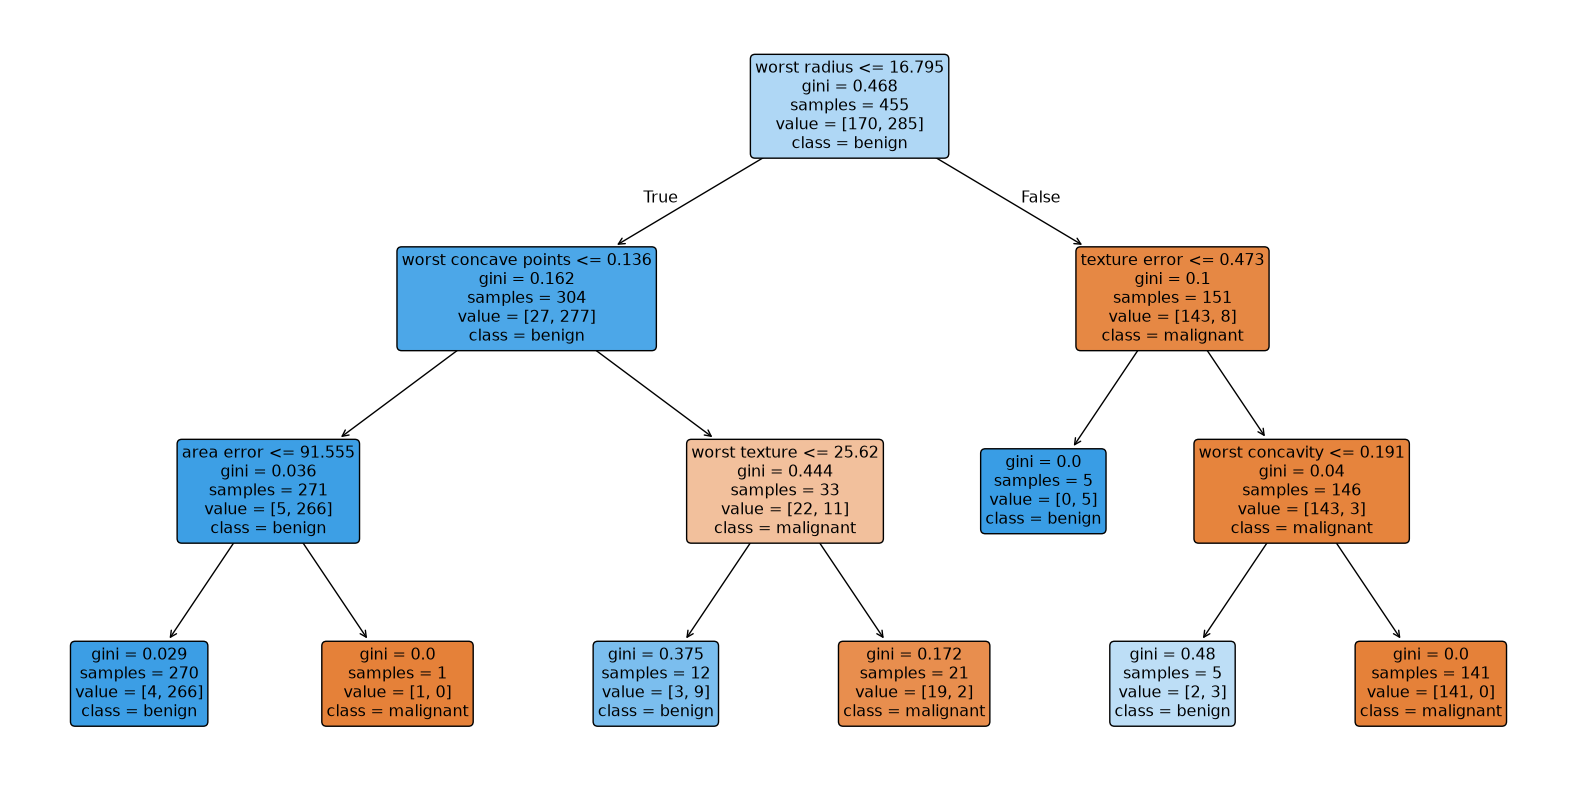

In [15]:
# Lets visualise the tree
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))
plot_tree(
    model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True
)

plt.show()

In [16]:
sample = X_test.iloc[[0]]

print(sample)
print("Actual class:", y_test.iloc[0] if hasattr(y_test, "iloc") else y_test[0])
print("Predicted class:", model.predict(sample)[0])

     mean radius  mean texture  ...  worst symmetry  worst fractal dimension
256        19.55         28.77  ...          0.2818                   0.1005

[1 rows x 30 columns]
Actual class: 0
Predicted class: 0


In [26]:
print(sample["worst radius"].iloc[0])
print(sample["worst concave points"].iloc[0])
print(sample["texture error"].iloc[0])
print(sample["worst concavity"].iloc[0])

25.05
0.1941
1.199
0.4251


In [20]:
path = model.decision_path(sample)
print(path.indices)

[ 0  8 10 12]


In [23]:
from sklearn.tree import export_text
tree_rules = export_text(
      model,
      feature_names=list(X.columns)
  )
  
print(tree_rules)

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 91.56
|   |   |   |--- class: 1
|   |   |--- area error >  91.56
|   |   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- class: 1
|   |   |--- worst texture >  25.62
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: 0



In [27]:
#now lets change the depth of the model
model5 = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

model5.fit(X_train, y_train)

y_pred5 = model5.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred5))
print("Malignant Recall:", recall_score(y_test, y_pred5, pos_label=0))

Accuracy: 0.9210526315789473
Malignant Recall: 0.9285714285714286


In [28]:
print("Depth 3:")
print(confusion_matrix(y_test, y_pred))

print("Depth 5:")
print(confusion_matrix(y_test, y_pred5))


Depth 3:
[[38  4]
 [ 3 69]]
Depth 5:
[[39  3]
 [ 6 66]]


In [29]:
from sklearn.metrics import accuracy_score

print("Depth 3 Training Accuracy:",
      accuracy_score(y_train, model.predict(X_train)))

print("Depth 3 Testing Accuracy:",
      accuracy_score(y_test, y_pred))

print("Depth 5 Training Accuracy:",
      accuracy_score(y_train, model5.predict(X_train)))

print("Depth 5 Testing Accuracy:",
      accuracy_score(y_test, y_pred5))

Depth 3 Training Accuracy: 0.9758241758241758
Depth 3 Testing Accuracy: 0.9385964912280702
Depth 5 Training Accuracy: 0.9934065934065934
Depth 5 Testing Accuracy: 0.9210526315789473


In [30]:
#Lets do cross validation by 5 folds(4 training and 1 validation):

from sklearn.model_selection import cross_val_score

for depth in [2,3,4,5,None]:
    model_cv = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    scores = cross_val_score(
        model_cv,
        X_train,
        y_train,
        cv = 5,
        scoring="accuracy"
    )

    print("Depth:", depth)
    print("Fold scores:", scores)
    print("Mean accuracy:", scores.mean())
    print()

Depth: 2
Fold scores: [0.93406593 0.93406593 0.9010989  0.89010989 0.93406593]
Mean accuracy: 0.9186813186813186

Depth: 3
Fold scores: [0.93406593 0.92307692 0.9010989  0.9010989  0.96703297]
Mean accuracy: 0.9252747252747252

Depth: 4
Fold scores: [0.93406593 0.94505495 0.91208791 0.93406593 0.96703297]
Mean accuracy: 0.9384615384615385

Depth: 5
Fold scores: [0.94505495 0.94505495 0.9010989  0.91208791 0.95604396]
Mean accuracy: 0.9318681318681318

Depth: None
Fold scores: [0.91208791 0.9010989  0.9010989  0.89010989 0.94505495]
Mean accuracy: 0.9098901098901099



In [41]:
#now lets change the depth of the model to 4 and compare it with 3
model4 = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

model4.fit(X_train, y_train)

y_pred4 = model4.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred4))
print("Malignant Recall:", recall_score(y_test, y_pred4, pos_label=0))

Accuracy: 0.9385964912280702
Malignant Recall: 0.9285714285714286


In [42]:
#lets do post pruning ccp_alpha
import numpy as np
alphas = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.02]

for alpha in alphas:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        ccp_alpha=alpha,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    print("Alpha:", alpha)
    print("Fold scores:", np.round(scores, 4))
    print("Mean accuracy:", round(scores.mean(), 4))
    print()

Alpha: 0.0001
Fold scores: [0.9341 0.9451 0.9121 0.9341 0.967 ]
Mean accuracy: 0.9385

Alpha: 0.0005
Fold scores: [0.9341 0.9451 0.9121 0.9341 0.967 ]
Mean accuracy: 0.9385

Alpha: 0.001
Fold scores: [0.9341 0.9451 0.9121 0.9341 0.967 ]
Mean accuracy: 0.9385

Alpha: 0.005
Fold scores: [0.9231 0.9451 0.9231 0.9451 0.967 ]
Mean accuracy: 0.9407

Alpha: 0.01
Fold scores: [0.9341 0.9451 0.9231 0.9231 0.967 ]
Mean accuracy: 0.9385

Alpha: 0.02
Fold scores: [0.9341 0.9451 0.9011 0.8901 0.967 ]
Mean accuracy: 0.9275



In [43]:
pruned_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    ccp_alpha=0.005,
    random_state=42
)

pruned_model.fit(X_train, y_train)

y_pred_pruned = pruned_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_pruned))

cm = confusion_matrix(y_test, y_pred_pruned, labels=[0, 1])
print("Confusion Matrix:\n", cm)

malignant_recall = cm[0, 0] / (cm[0, 0] + cm[0, 1])
print("Malignant Recall:", malignant_recall)

Test Accuracy: 0.9385964912280702
Confusion Matrix:
 [[39  3]
 [ 4 68]]
Malignant Recall: 0.9285714285714286


In [45]:
print("Unpruned depth:", model4.get_depth())
print("Unpruned leaves:", model4.get_n_leaves())

print("Pruned depth:", pruned_model.get_depth())
print("Pruned leaves:", pruned_model.get_n_leaves())

Unpruned depth: 4
Unpruned leaves: 11
Pruned depth: 4
Pruned leaves: 9


In [46]:
#min sample split
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
import numpy as np

split_values = [2, 5, 10, 20, 30]

for value in split_values:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_split=value,
        ccp_alpha=0.005,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    print("min_samples_split:", value)
    print("Fold scores:", np.round(scores, 4))
    print("Mean accuracy:", round(scores.mean(), 4))
    print()

min_samples_split: 2
Fold scores: [0.9231 0.9451 0.9231 0.9451 0.967 ]
Mean accuracy: 0.9407

min_samples_split: 5
Fold scores: [0.9231 0.9451 0.9231 0.9231 0.967 ]
Mean accuracy: 0.9363

min_samples_split: 10
Fold scores: [0.9231 0.9451 0.9231 0.9011 0.967 ]
Mean accuracy: 0.9319

min_samples_split: 20
Fold scores: [0.9121 0.9121 0.9011 0.9011 0.967 ]
Mean accuracy: 0.9187

min_samples_split: 30
Fold scores: [0.9121 0.9121 0.9011 0.9011 0.967 ]
Mean accuracy: 0.9187



In [47]:
#min sample leaf
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
import numpy as np

leaf_values = [1, 2, 5, 10, 15, 20]

for value in leaf_values:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_split=2,
        min_samples_leaf=value,
        ccp_alpha=0.005,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    print("min_samples_leaf:", value)
    print("Fold scores:", np.round(scores, 4))
    print("Mean accuracy:", round(scores.mean(), 4))
    print()

min_samples_leaf: 1
Fold scores: [0.9231 0.9451 0.9231 0.9451 0.967 ]
Mean accuracy: 0.9407

min_samples_leaf: 2
Fold scores: [0.9231 0.9451 0.9231 0.9231 0.956 ]
Mean accuracy: 0.9341

min_samples_leaf: 5
Fold scores: [0.9341 0.9451 0.9341 0.8901 0.967 ]
Mean accuracy: 0.9341

min_samples_leaf: 10
Fold scores: [0.9121 0.9341 0.8901 0.8901 0.967 ]
Mean accuracy: 0.9187

min_samples_leaf: 15
Fold scores: [0.9341 0.9231 0.9011 0.9011 0.9231]
Mean accuracy: 0.9165

min_samples_leaf: 20
Fold scores: [0.9231 0.8901 0.9011 0.9011 0.9121]
Mean accuracy: 0.9055



In [ ]:
# GRID SEARCH CV

from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    "max_depth": [3, 4, 5, 6],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "ccp_alpha": [0, 0.001, 0.005, 0.01]
}

model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

best_model = grid_search.best_estimator_

y_pred_grid = best_model.predict(X_test)

from sklearn.metrics import accuracy_score, confusion_matrix

print("Test Accuracy:", accuracy_score(y_test, y_pred_grid))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_grid, labels=[0, 1]))

Best Parameters: {'ccp_alpha': 0.005, 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Accuracy: 0.9406593406593406
Test Accuracy: 0.9385964912280702
Confusion Matrix:
 [[39  3]
 [ 4 68]]
